# 03 — Machine learning: Regressão Linear × Random Forest

O ML é usado como **ferramenta de análise**: comparar quanto câmbio, clima e sazonalidade explicam os preços de cada commodity. Validação com `TimeSeriesSplit` (treino sempre anterior ao teste) e métricas MAE, RMSE e R². Features de clima defasadas em 21 dias úteis.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
from src import config
from src.analise.estilo import aplicar_estilo_matplotlib

aplicar_estilo_matplotlib()
pd.set_option("display.max_columns", 50)

In [2]:
from src.modelagem import modelos
from src.pipeline import carregar_base

df = carregar_base()
metricas, importancias = modelos.executar(df)

09:52:09 INFO    src.modelagem.modelos: R2 de ajuste (serie completa, poder explicativo): linear=0.315  random_forest=0.977


09:52:10 INFO    src.modelagem.modelos: cafe / nivel (1600 obs):
                    MAE     RMSE     R2
modelo                                 
baseline_media  532.452  574.265 -7.636
linear          595.017  639.298 -9.936
random_forest   623.827  674.073 -9.756


09:52:14 INFO    src.modelagem.modelos: R2 de ajuste (serie completa, poder explicativo): linear=0.090  random_forest=0.946


09:52:14 INFO    src.modelagem.modelos: cafe / var_21d (1600 obs):
                  MAE    RMSE     R2
modelo                              
baseline_media  8.076  10.565 -0.266
linear          9.815  11.951 -0.701
random_forest   8.842  11.045 -0.404


09:52:18 INFO    src.modelagem.modelos: R2 de ajuste (serie completa, poder explicativo): linear=0.347  random_forest=0.979


09:52:18 INFO    src.modelagem.modelos: soja / nivel (1600 obs):
                   MAE    RMSE      R2
modelo                                
baseline_media  23.125  24.991 -10.489
linear          28.121  31.237 -16.830
random_forest   23.010  27.479 -11.050


09:52:21 INFO    src.modelagem.modelos: R2 de ajuste (serie completa, poder explicativo): linear=0.185  random_forest=0.929


09:52:21 INFO    src.modelagem.modelos: soja / var_21d (1600 obs):
                  MAE   RMSE     R2
modelo                             
baseline_media  3.905  5.058 -0.225
linear          4.759  5.794 -0.689
random_forest   4.841  6.027 -0.994


09:52:22 INFO    src.modelagem.modelos: reports/modelos/: metricas e importancias salvas


## Métricas por fold

In [3]:
metricas.groupby(["produto", "alvo", "modelo"])[["MAE", "RMSE", "R2"]].mean().round(3)

MAE     RMSE      R2
produto alvo    modelo                                  
cafe    nivel   baseline_media  532.452  574.265  -7.636
                linear          595.017  639.298  -9.936
                random_forest   623.827  674.073  -9.756
        var_21d baseline_media    8.076   10.565  -0.266
                linear            9.815   11.951  -0.701
                random_forest     8.842   11.045  -0.404
soja    nivel   baseline_media   23.125   24.991 -10.489
                linear           28.121   31.237 -16.830
                random_forest    23.010   27.479 -11.050
        var_21d baseline_media    3.905    5.058  -0.225
                linear            4.759    5.794  -0.689
                random_forest     4.841    6.027  -0.994

In [4]:
metricas.pivot_table(index=["produto", "alvo", "fold"], columns="modelo", values="R2").round(3)

modelo                baseline_media  linear  random_forest
produto alvo    fold                                       
cafe    nivel   1            -21.458 -29.209        -22.284
                2             -0.085  -1.044         -2.291
                3             -0.396  -1.297         -1.562
                4            -11.143 -11.367        -12.058
                5             -5.098  -6.763        -10.584
        var_21d 1             -0.090  -1.561         -0.529
                2             -0.713  -1.243         -0.616
                3             -0.191  -0.124         -0.120
                4             -0.014  -0.040          0.008
                5             -0.325  -0.536         -0.766
soja    nivel   1             -4.324 -14.448         -6.904
                2             -0.122  -0.620         -1.974
                3            -12.973 -20.359         -9.418
                4            -33.478 -48.279        -36.009
                5             -1.548  -0.446         -0.943
        var_21d 1             -0.272  -2.071         -1.933
                2             -0.677  -0.769         -0.976
                3             -0.048  -0.221         -0.454
                4             -0.097  -0.542         -2.068
                5             -0.030   0.159          0.460

## Coeficientes (LR padronizada) × importância (RF)

In [5]:
importancias[(importancias["produto"] == "cafe") & (importancias["alvo"] == "nivel")].round(3)

,produto,alvo,feature,grupo,coef_padronizado,importancia_lr,importancia_rf
0,cafe,nivel,dolar_lag20,cambio,175.851,0.113,0.338
1,cafe,nivel,anomalia_chuva_90d_lag21,clima,-112.612,0.072,0.155
2,cafe,nivel,temp_min_30d_lag21,clima,-194.405,0.125,0.096
3,cafe,nivel,dolar_lag1,cambio,63.888,0.041,0.069
4,cafe,nivel,dolar_lag5,cambio,34.515,0.022,0.067
5,cafe,nivel,chuva_90d_lag21,clima,333.585,0.214,0.058
6,cafe,nivel,chuva_180d_lag21,clima,-158.233,0.101,0.057
7,cafe,nivel,temp_max_30d_lag21,clima,162.014,0.104,0.055
8,cafe,nivel,chuva_30d_lag21,clima,55.919,0.036,0.039
9,cafe,nivel,mes_cos,sazonalidade,-202.283,0.130,0.032


In [6]:
importancias[(importancias["produto"] == "soja") & (importancias["alvo"] == "nivel")].round(3)

,produto,alvo,feature,grupo,coef_padronizado,importancia_lr,importancia_rf
22,soja,nivel,anomalia_chuva_90d_lag21,clima,5.102,0.080,0.292
23,soja,nivel,chuva_180d_lag21,clima,9.444,0.149,0.144
24,soja,nivel,temp_min_30d_lag21,clima,-8.404,0.132,0.113
25,soja,nivel,chuva_30d_lag21,clima,6.194,0.098,0.078
26,soja,nivel,dolar_lag1,cambio,2.433,0.038,0.075
27,soja,nivel,dolar_lag20,cambio,-2.601,0.041,0.074
28,soja,nivel,temp_max_30d_lag21,clima,1.102,0.017,0.056
29,soja,nivel,chuva_90d_lag21,clima,5.398,0.085,0.051
30,soja,nivel,dolar_lag5,cambio,-1.370,0.022,0.047
31,soja,nivel,mes_cos,sazonalidade,10.670,0.168,0.028


## Importância por grupo — resposta à P6

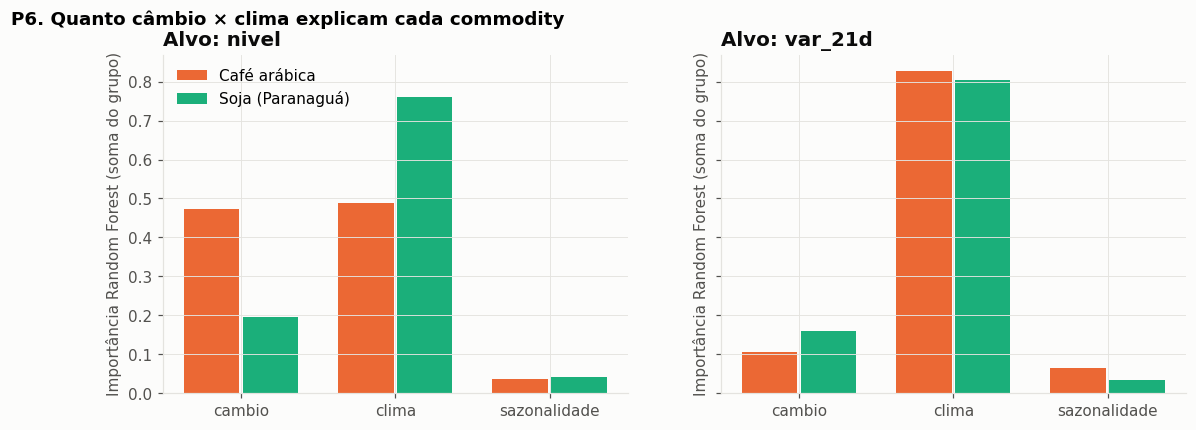

In [7]:
modelos.grafico_importancia_grupos(importancias);

In [8]:
importancias.groupby(["produto", "alvo", "grupo"])[["importancia_lr", "importancia_rf"]].sum().round(3)

importancia_lr  importancia_rf
produto alvo    grupo                                       
cafe    nivel   cambio                 0.176           0.474
                clima                  0.655           0.489
                sazonalidade           0.170           0.037
        var_21d cambio                 0.121           0.106
                clima                  0.772           0.828
                sazonalidade           0.108           0.066
soja    nivel   cambio                 0.101           0.196
                clima                  0.702           0.762
                sazonalidade           0.198           0.042
        var_21d cambio                 0.116           0.161
                clima                  0.720           0.805
                sazonalidade           0.164           0.034

### Interpretação
- R² fora da amostra baixo/negativo é esperado: preços de commodities mudam de patamar e modelos treinados no passado não extrapolam. Compare sempre com `baseline_media`.
- O que interessa é **qual grupo** (câmbio, clima, sazonalidade) concentra a importância em cada commodity.